# Experimental pipeline: stereo 3D shape reconstruction + sensor regression

Grid run `sw/data/experimental/<RUN>/`: the fiber tip (green LED clip) was moved through a 5 x 5 grid of positions. For each
position there is a left/right camera image (`grid_data/img_rXX_cYY_{l,r}.png`) and ~5 s of photodiode readings
(`sensor_data/img_rXX_cYY.csv`).

1. **CV segmentation** (per image): green tip LED → Sato dark-ridge filter → minimum-cost path from the clamp to the tip.
2. **Stereo pose**: intrinsics from `calib/stereo_calib.json` (scaled 1280x720 → 1920x1080). The saved extrinsics belong to an
   earlier camera arrangement, so R, t are re-estimated from the 25 tip correspondences (5-point essential matrix).
3. **3D reconstruction**: epipolar matching of the two centerlines → triangulation → smoothed 3D curve in a clamp frame
   (origin at the top of the fiber, z up, x along the grid columns), resampled at `N_PTS` points by arc length.
4. **Regression**: ridge regression from the photodiode channels (`vo_k / vref`) to the 3D curve, evaluated with nested
   leave-one-out cross-validation.

Units: the stereo baseline is unknown (the old calibration no longer applies), so the reconstruction is only defined up
to scale. Lengths are expressed in **units of the fiber's visible length** (L = 1) unless `FIBER_LENGTH_MM` is set.

In [1]:
# config + data loading
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# repo's sw/ folder: walk up from the notebook's working directory
SW = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "calib").is_dir() and (p / "data").is_dir()),
          Path(r"C:\Users\alagi\shape-sensing\sw"))
RUN = SW / "data" / "experimental" / "2026-11-18T17"
GRID_DIR, SENSOR_DIR = RUN / "grid_data", RUN / "sensor_data"

N_PTS = 50              # points per reconstructed 3D curve (clamp -> tip, uniform in arc length)
FIBER_LENGTH_MM = None  # visible fiber length (top of right camera's view -> LED clip) in mm; None = normalised units
CHANNELS = [f"vo{k}_uv" for k in range(1, 8)]

# figure colours (validated reference palette): measured = blue, predicted = orange, sequential ramp = blue
C_MEAS, C_PRED, C_AUX = "#2a78d6", "#eb6834", "#1baf7a"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "lines.linewidth": 2, "font.size": 9})

log = pd.read_csv(GRID_DIR / "log.csv")
log["name"] = log["file"].str[:-6]                       # img_rXX_cYY
log["cam_side"] = log["file"].str[-5]                    # l / r
names = sorted(log["name"].unique())
grid = log.drop_duplicates("name").set_index("name")[["row", "col", "timestamp", "sensor_file"]].loc[names]
grid["order"] = pd.to_datetime(grid["timestamp"]).rank().astype(int)     # capture order (for drift checks)
N_ROWS, N_COLS = grid["row"].max() + 1, grid["col"].max() + 1

images = {n: {s: cv2.imread(str(GRID_DIR / f"{n}_{s}.png")) for s in "lr"} for n in names}
H, W = images[names[0]]["l"].shape[:2]

# sensors: mean of each snapshot; divide by vref to cancel source drift
sens = []
for n in names:
    d = pd.read_csv(SENSOR_DIR / grid.loc[n, "sensor_file"])
    row = {"name": n, "n_samples": len(d), "vref_uv": d["vref_uv"].mean()}
    row |= {c: d[c].mean() for c in CHANNELS}
    row |= {c.replace("_uv", "_sd"): d[c].std() for c in CHANNELS}
    sens.append(row)
sens = pd.DataFrame(sens).set_index("name")
for c in CHANNELS:
    sens[c.replace("_uv", "_rel")] = sens[c] / sens["vref_uv"]
REL = [c.replace("_uv", "_rel") for c in CHANNELS]
# vo7 / vref is constant to <0.05 % over the whole run: channel 7 only follows vref (photodiode off / unused),
# so it carries no shape information and is left out of the regression features
FEATURES = [f for f in REL if f != "vo7_rel"]

print(f"{len(names)} positions ({N_ROWS} x {N_COLS}), images {W}x{H}, run {RUN.name}")
print(f"sensor snapshots: {sens['n_samples'].min()}-{sens['n_samples'].max()} samples, "
      f"max within-snapshot std {sens[[c.replace('_uv', '_sd') for c in CHANNELS]].max().max():.0f} uV")

25 positions (5 x 5), images 1920x1080, run 2026-11-18T17
sensor snapshots: 10-11 samples, max within-snapshot std 61 uV


## 1. CV segmentation

Black fiber on a white backdrop, so the fiber is a **dark ridge** about 10-14 px wide. Per image:

* **Tip**: largest saturated-green blob in the lower part of the image (closed so the cords crossing the clip don't split it).
* **Ridge map**: Sato filter (`black_ridges=True`) on grayscale at scales near the fiber radius. The thin crossing cords and
  frame edges respond much less at these scales.
* **Path**: minimum-cost path (`MCP_Geometric`) on cost = 1 / (ridge + ε)², from the clamp to the tip. Both endpoints are
  known, so the path can't wander off onto cables the way step-by-step tracking can. In the right camera the clamp is just
  above the frame, so that path may start anywhere along a short span of the top row.
* The path is cut where it enters the LED clip, resampled to 1 px steps and lightly smoothed.

In [2]:
# segmentation
from skimage.filters import sato
from skimage.graph import MCP_Geometric

ROI_X = (450, 1550)        # the fiber stays between the two front posts [px]
SIGMAS = (3, 4.5, 6)       # Sato scales [px] ~ fiber radius
CLAMP = {"l": [(987, 40)],                               # clamp exit point, left camera
         "r": [(x, 1) for x in range(880, 985, 3)]}      # right camera: clamp is above the frame, enter via the top row
TIP_HUE, TIP_MIN_Y = (45, 90), 600                       # green LED (OpenCV hue 0..180); tip is in the lower image


def green_tip(img):
    h, s, v = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))
    m = ((h > TIP_HUE[0]) & (h < TIP_HUE[1]) & (s > 100) & (v > 120)).astype(np.uint8)
    m[:TIP_MIN_Y] = 0
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31)))
    n, lab, st, cen = cv2.connectedComponentsWithStats(m)
    if n < 2:
        raise RuntimeError("green tip not found")
    i = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
    return cen[i], (lab == i).astype(np.uint8)


def ridge_map(img):
    x0, x1 = ROI_X
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)[:, x0:x1]
    R = np.zeros(img.shape[:2], np.float32)
    R[:, x0:x1] = sato(g, sigmas=SIGMAS, black_ridges=True)
    return R / np.percentile(R[R > 0], 99.5)


def resample(p, step=1.0):
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    keep = np.r_[True, np.diff(s) > 1e-9]
    p, s = p[keep], s[keep]
    u = np.arange(0, s[-1], step)
    return np.column_stack([np.interp(u, s, p[:, k]) for k in range(p.shape[1])])


def smooth(p, k=9):
    pad = np.pad(p, ((k // 2, k // 2), (0, 0)), mode="edge")
    return np.column_stack([np.convolve(pad[:, j], np.ones(k) / k, "valid") for j in range(p.shape[1])])


def segment(img, cam):
    tip, tmask = green_tip(img)
    R = ridge_map(img)
    cost = 1.0 / (0.02 + np.clip(R, 0, 1)) ** 2
    cost[:, :ROI_X[0]] = cost[:, ROI_X[1]:] = 1e6
    mcp = MCP_Geometric(cost)
    end = (int(tip[1]), int(tip[0]))
    mcp.find_costs([(y, x) for x, y in CLAMP[cam]], [end])
    path = np.array(mcp.traceback(end))[:, ::-1].astype(float)          # (x, y), clamp -> tip
    inside = cv2.dilate(tmask, np.ones((9, 9), np.uint8))[path[:, 1].astype(int), path[:, 0].astype(int)] > 0
    path = path[: np.argmax(inside) + 1] if inside.any() else path      # stop at the LED clip
    return dict(centerline=smooth(resample(path)), raw=path, tip=tip, tip_mask=tmask, ridge=R)


seg = {}
for n in names:
    seg[n] = {}
    for cam in "lr":
        try:
            seg[n][cam] = segment(images[n][cam], cam)
        except RuntimeError as e:
            print(f"{n}_{cam}: segmentation FAILED ({e})")
lens = pd.DataFrame({cam: [len(seg[n][cam]["centerline"]) for n in names] for cam in "lr"}, index=names)
print(f"segmented {sum(len(v) for v in seg.values())}/{2 * len(names)} images; "
      f"centerline length [px] left {lens['l'].min()}-{lens['l'].max()}, right {lens['r'].min()}-{lens['r'].max()}")

segmented 50/50 images; centerline length [px] left 836-1042, right 835-1039


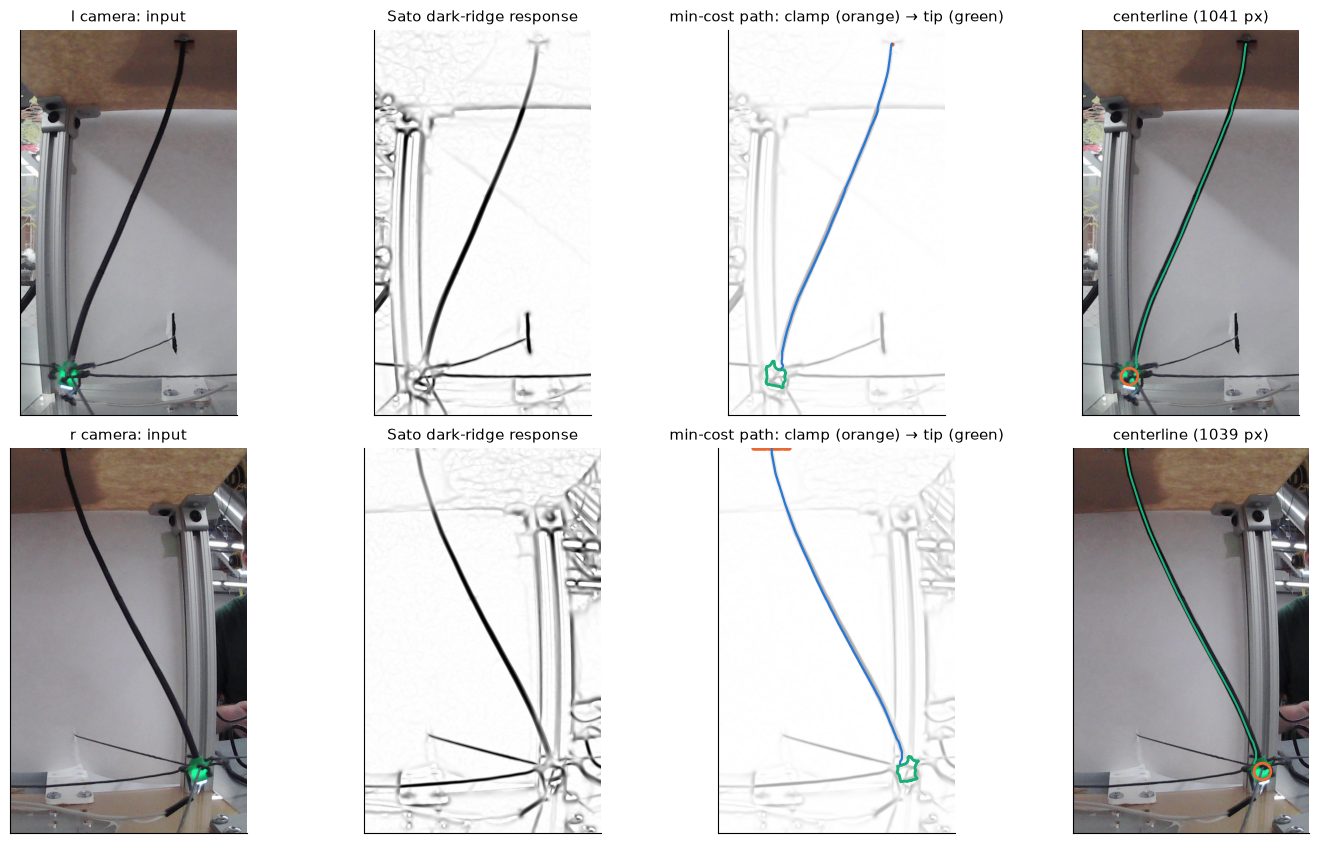

In [3]:
# figure: segmentation steps for one position (rows: left / right camera)
EXAMPLE = "img_r00_c00"

fig, axes = plt.subplots(2, 4, figsize=(15, 8.5))
for row, cam in enumerate("lr"):
    img, r = images[EXAMPLE][cam], seg[EXAMPLE][cam]
    cl = r["centerline"]
    x0, x1 = int(cl[:, 0].min()) - 150, int(cl[:, 0].max()) + 150
    ext = (x0, x1, H, 0)
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)[:, x0:x1]
    ax = axes[row]
    ax[0].imshow(rgb, extent=ext)
    ax[0].set_title(f"{cam} camera: input")
    ax[1].imshow(r["ridge"][:, x0:x1], cmap="gray_r", vmin=0, vmax=1, extent=ext)
    ax[1].set_title("Sato dark-ridge response")
    ax[2].imshow(np.clip(r["ridge"][:, x0:x1], 0, 1), cmap="gray_r", vmin=0, vmax=3, extent=ext)
    ax[2].contour(np.arange(x0, x1), np.arange(H), r["tip_mask"][:, x0:x1], [0.5], colors=C_AUX, linewidths=2)
    ax[2].plot(*np.array(CLAMP[cam]).T, ".", color=C_PRED, ms=4)
    ax[2].plot(*r["raw"].T, color=C_MEAS, lw=1.5)
    ax[2].set_title("min-cost path: clamp (orange) → tip (green)")
    ax[3].imshow(rgb, extent=ext)
    ax[3].plot(*cl.T, color=C_AUX, lw=1.5)
    ax[3].plot(*r["tip"], "o", mfc="none", mec=C_PRED, ms=12, mew=2)
    ax[3].set_title(f"centerline ({len(cl)} px)")
    for a in ax:
        a.set_xlim(x0, x1); a.set_ylim(H, 0); a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

## 2. Stereo pose from the tip correspondences

The intrinsics (K, distortion) come from the 1280x720 calibration and are scaled by 1.5 for these 1920x1080 images (same
16:9 field of view). The **saved extrinsics don't fit this rig**: the first cell below shows the epipolar error they give.
The tip moves *right* in the left camera but *left* in the right camera across a grid row, so the cameras now look at the
fiber from roughly perpendicular directions, not as a 62 mm parallel pair.

R and t are therefore re-estimated from the 25 tip-LED correspondences (5-point essential matrix + RANSAC). The
translation is only known up to scale (|t| = 1).

In [4]:
# stereo pose
calib = {k: np.array(v) for k, v in json.loads((SW / "calib" / "stereo_calib.json").read_text()).items() if isinstance(v, list)}
s_img = W / calib["image_size"][0]
K0, K1 = calib["K0"].copy(), calib["K1"].copy()
K0[:2] *= s_img
K1[:2] *= s_img
D0, D1 = calib["D0"], calib["D1"]
f_px = np.sqrt(K0[0, 0] * K1[0, 0])


def undist(uv, K, D):
    return cv2.undistortPoints(np.asarray(uv, np.float64).reshape(-1, 1, 2), K, D).reshape(-1, 2)


def skew(t):
    return np.array([[0, -t[2], t[1]], [t[2], 0, -t[0]], [-t[1], t[0], 0]])


def epi_err_px(E, n0, n1):
    l = np.c_[n0, np.ones(len(n0))] @ E.T
    return np.abs(np.sum(np.c_[n1, np.ones(len(n1))] * l, 1)) / np.linalg.norm(l[:, :2], axis=1) * f_px


tips = np.array([[seg[n][c]["tip"] for c in "lr"] for n in names])        # (N, 2 cams, 2)
n0, n1 = undist(tips[:, 0], K0, D0), undist(tips[:, 1], K1, D1)
e_old = epi_err_px(calib["E"], n0, n1)
print(f"saved calibration: tip epipolar error median {np.median(e_old):.0f} px, max {e_old.max():.0f} px  -> not usable")

E, inl = cv2.findEssentialMat(n0, n1, np.eye(3), cv2.RANSAC, 0.999, 4 / f_px)
_, R, t, _ = cv2.recoverPose(E, n0, n1, np.eye(3), mask=inl.copy())
t = t.ravel()
E = skew(t) @ R
e_new = epi_err_px(E, n0, n1)
C1 = -R.T @ t                                                              # right camera centre in the left camera frame
print(f"re-estimated: {inl.sum()}/{len(names)} RANSAC inliers, tip epipolar error median {np.median(e_new):.1f} px, "
      f"max {e_new.max():.1f} px")
print(f"relative rotation {np.degrees(np.linalg.norm(cv2.Rodrigues(R)[0])):.1f} deg, "
      f"right camera centre (left-cam frame, |t|=1) {np.round(C1, 3)}")

saved calibration: tip epipolar error median 93 px, max 429 px  -> not usable
re-estimated: 20/25 RANSAC inliers, tip epipolar error median 2.3 px, max 13.1 px
relative rotation 89.3 deg, right camera centre (left-cam frame, |t|=1) [-0.73   0.049  0.682]


## 3. 3D reconstruction

For every point on the left centerline, its epipolar line is intersected with the right centerline. The fiber runs roughly
vertically in both images and the epipolar lines run roughly horizontally, so there is a single, well-conditioned crossing.
Points with no unique crossing, or where the line grazes the curve, are dropped. The matched pairs are triangulated, then
smoothed and resampled to `N_PTS` points by arc length.

Clamp frame: origin = mean start point of the curves (the top of the fiber where both cameras see it), **z up** (away from
the mean tip), **x** along the grid columns (c0 → c4), y = z × x.

In [5]:
# triangulate the centerlines
from scipy.interpolate import make_smoothing_spline


def match_epipolar(m0, m1, E, min_sin=0.25):
    # for each left point (normalised coords), its unique crossing with the right curve; returns (idx, right pts)
    h1 = np.c_[m1, np.ones(len(m1))]
    idx, pts = [], []
    for i, q in enumerate(m0):
        l = E @ np.r_[q, 1]
        d = h1 @ l / np.linalg.norm(l[:2])
        sc = np.flatnonzero(np.sign(d[:-1]) != np.sign(d[1:]))
        if len(sc) != 1:
            continue
        j = sc[0]
        seg_ = m1[j + 1] - m1[j]
        u, v = seg_ / (np.linalg.norm(seg_) + 1e-12), np.array([-l[1], l[0]]) / np.linalg.norm(l[:2])
        if abs(u[0] * v[1] - u[1] * v[0]) < min_sin:                    # line nearly parallel to the curve
            continue
        idx.append(i)
        pts.append(m1[j] + d[j] / (d[j] - d[j + 1]) * seg_)
    return np.array(idx), np.array(pts)


def triangulate(m0, m1):
    X = cv2.triangulatePoints(np.eye(3, 4), np.c_[R, t], m0.T, m1.T)
    return (X[:3] / X[3]).T


def smooth_curve(X, n=N_PTS, lam=None):
    # smoothing spline per coordinate vs arc length, resampled uniformly in arc length
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(X, axis=0), axis=1))]
    keep = np.r_[True, np.diff(s) > 1e-9]
    X, s = X[keep], s[keep]
    lam = lam if lam is not None else 1e-4 * s[-1] ** 3
    sp = [make_smoothing_spline(s, X[:, k], lam=lam) for k in range(3)]
    tt = np.linspace(0, s[-1], 20 * n)
    Y = np.column_stack([f(tt) for f in sp])
    sl = np.r_[0, np.cumsum(np.linalg.norm(np.diff(Y, axis=0), axis=1))]
    return np.column_stack([f(np.interp(np.linspace(0, sl[-1], n), sl, tt)) for f in sp])


recon = {}
for n in names:
    cl, cr = seg[n]["l"]["centerline"], seg[n]["r"]["centerline"]
    m0, m1 = undist(cl, K0, D0), undist(cr, K1, D1)
    idx, q1 = match_epipolar(m0, m1, E)
    Xc = triangulate(m0[idx], q1)                                       # left-camera frame, |t| = 1
    recon[n] = dict(idx=idx, uv_r=q1, X_cam=Xc, X_cam_s=smooth_curve(Xc), frac=len(idx) / len(cl))

# clamp frame
O = np.mean([recon[n]["X_cam_s"][0] for n in names], axis=0)
tip_cam = np.array([recon[n]["X_cam_s"][-1] for n in names])
ez = O - tip_cam.mean(0)
ez /= np.linalg.norm(ez)
G = tip_cam.reshape(N_ROWS, N_COLS, 3)
ex = (G[:, -1] - G[:, 0]).mean(0)
ex -= ex @ ez * ez
ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
R_wc = np.vstack([ex, ey, ez])                                          # camera -> clamp frame

L_raw = np.array([np.linalg.norm(np.diff(recon[n]["X_cam_s"], axis=0), axis=1).sum() for n in names])
SCALE = (FIBER_LENGTH_MM if FIBER_LENGTH_MM else 1.0) / np.median(L_raw)
UNIT = "mm" if FIBER_LENGTH_MM else "L"
for n in names:
    recon[n]["X"] = (recon[n]["X_cam_s"] - O) @ R_wc.T * SCALE
curves = np.stack([recon[n]["X"] for n in names])                       # (N, N_PTS, 3) in the clamp frame


# reprojection check: project the smoothed 3D curve back into both images
def project(Xc, cam):
    rv, tv, K, D = ((np.zeros(3), np.zeros(3), K0, D0) if cam == "l" else (cv2.Rodrigues(R)[0], t, K1, D1))
    return cv2.projectPoints(Xc.reshape(-1, 1, 3), rv, tv, K, D)[0].reshape(-1, 2)


def curve_dist_px(a, b):
    # mean distance from points a to polyline b (dense) [px]
    bd = resample(b, 0.5)
    return np.mean(np.min(np.linalg.norm(a[:, None] - bd[None], axis=2), axis=1))


for n in names:
    Xd = smooth_curve(recon[n]["X_cam"], n=300)
    recon[n]["reproj"] = {c: project(Xd, c) for c in "lr"}
    recon[n]["reproj_err"] = {c: curve_dist_px(recon[n]["reproj"][c], seg[n][c]["centerline"]) for c in "lr"}

shape_df = pd.DataFrame({
    "row": grid["row"], "col": grid["col"],
    "length": L_raw * SCALE,
    "matched_frac": [recon[n]["frac"] for n in names],
    "reproj_l_px": [recon[n]["reproj_err"]["l"] for n in names],
    "reproj_r_px": [recon[n]["reproj_err"]["r"] for n in names],
    "tip_x": curves[:, -1, 0], "tip_y": curves[:, -1, 1], "tip_z": curves[:, -1, 2],
}, index=names)
print(f"fiber length (should be constant): {shape_df['length'].mean():.3f} +- {shape_df['length'].std():.3f} {UNIT} "
      f"({100 * shape_df['length'].std() / shape_df['length'].mean():.1f} %)")
print(f"start-point spread: {np.linalg.norm([recon[n]['X'][0] for n in names], axis=1).mean():.4f} {UNIT}")
print(f"reprojection error: left {shape_df['reproj_l_px'].mean():.2f} px, right {shape_df['reproj_r_px'].mean():.2f} px (mean)")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(shape_df.describe().loc[["mean", "std", "min", "max"]])

fiber length (should be constant): 1.000 +- 0.010 L (1.0 %)
start-point spread: 0.0053 L
reprojection error: left 0.27 px, right 0.24 px (mean)


,row,col,length,matched_frac,reproj_l_px,reproj_r_px,tip_x,tip_y,tip_z
mean,2.000,2.000,1.000,0.954,0.266,0.244,0.000,0.000,-0.943
std,1.443,1.443,0.010,0.009,0.052,0.061,0.215,0.240,0.042
min,0.000,0.000,0.978,0.934,0.183,0.180,-0.354,-0.410,-1.004
max,4.000,4.000,1.014,0.966,0.417,0.413,0.401,0.411,-0.868


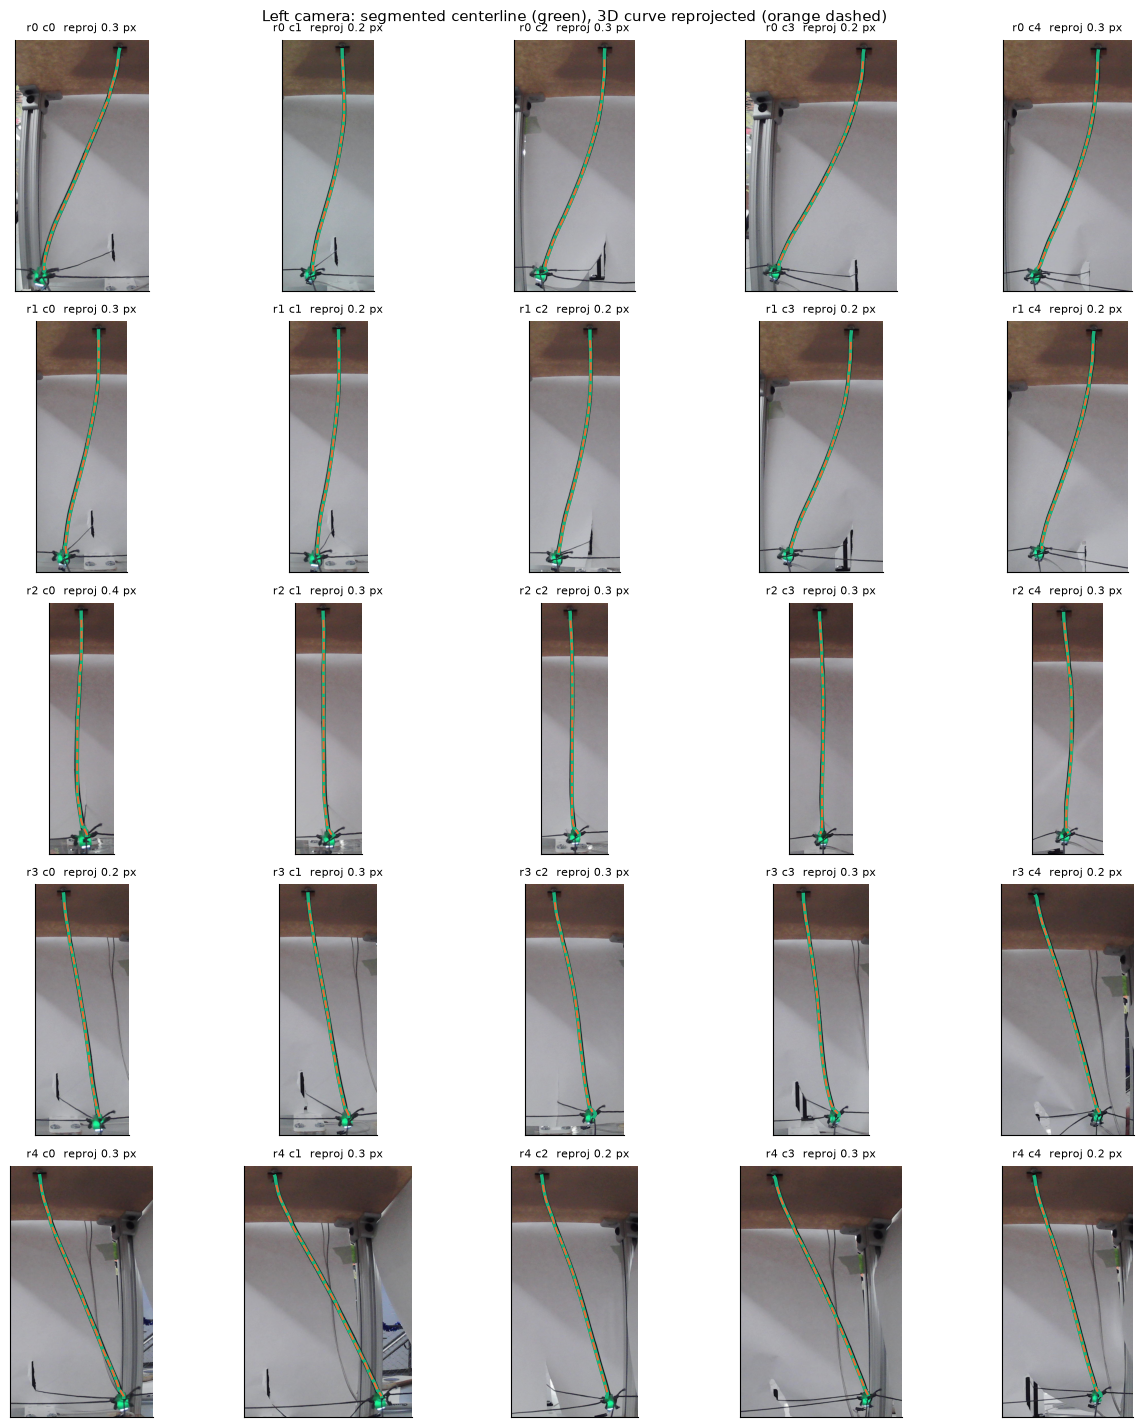

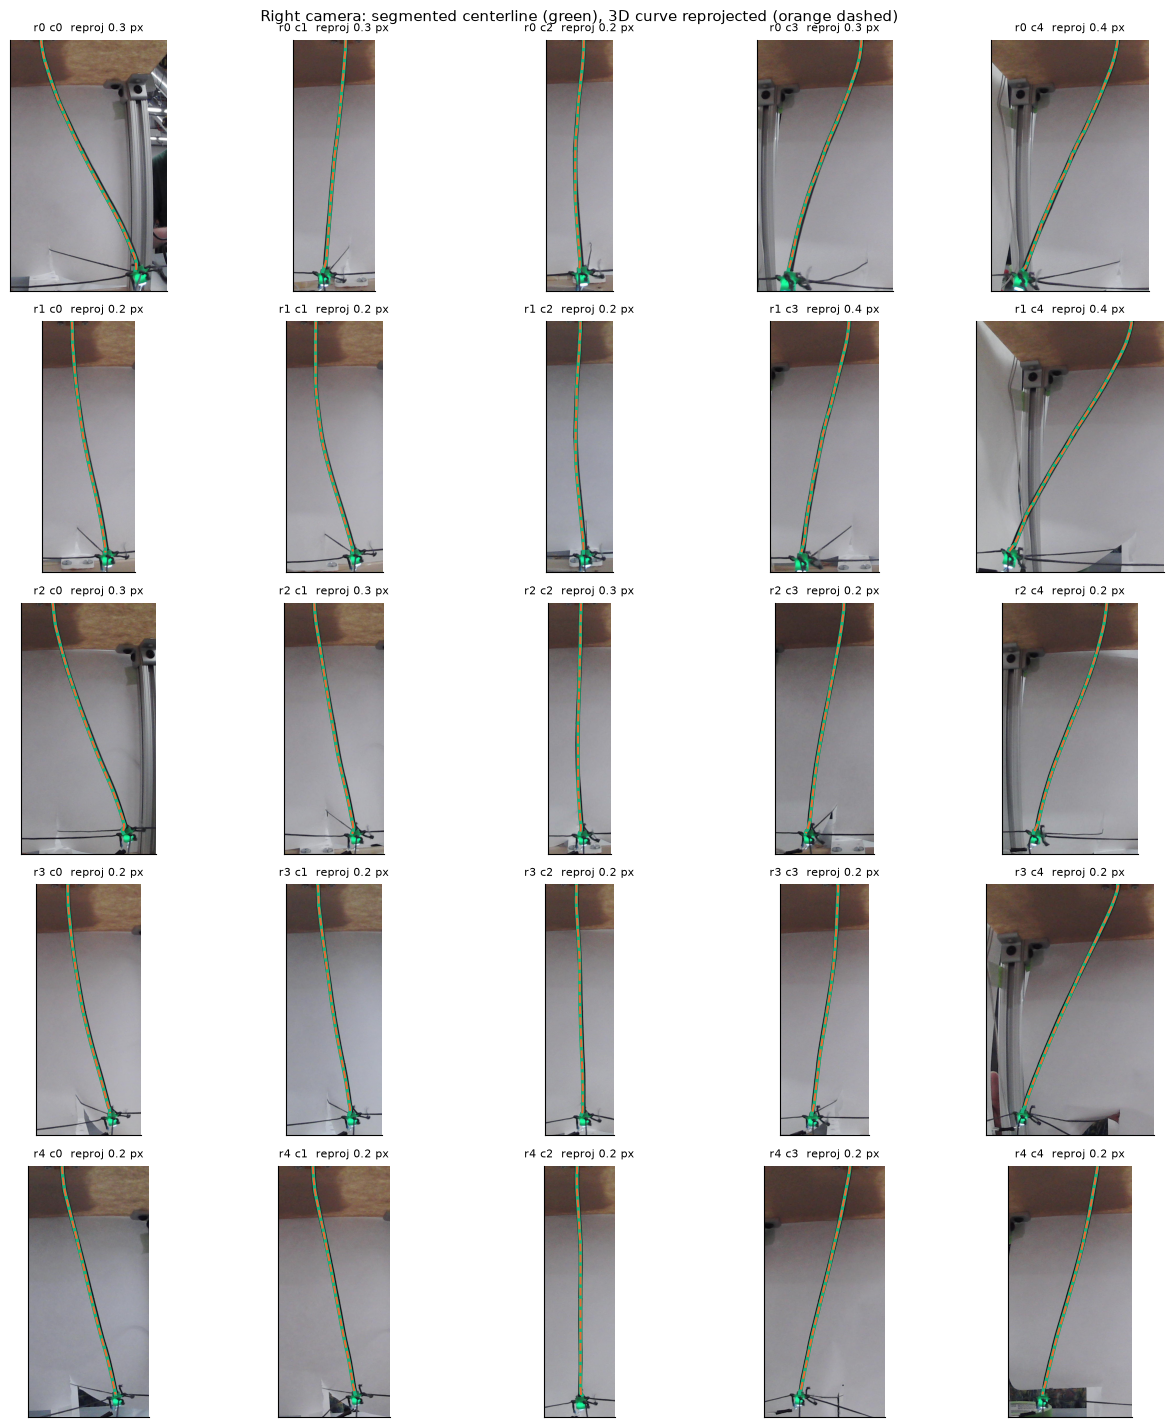

In [6]:
# figure: CV segmentation for every position -- 2D centerline (green) + reprojected 3D curve (orange dashed)
for cam in "lr":
    fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(2.6 * N_COLS, 2.9 * N_ROWS))
    for n in names:
        ax = axes[grid.loc[n, "row"], grid.loc[n, "col"]]
        cl, rp = seg[n][cam]["centerline"], recon[n]["reproj"][cam]
        x0, x1 = int(cl[:, 0].min()) - 120, int(cl[:, 0].max()) + 120
        y0, y1 = max(int(cl[:, 1].min()) - 60, 0), min(int(cl[:, 1].max()) + 80, H)
        ax.imshow(cv2.cvtColor(images[n][cam][y0:y1, x0:x1], cv2.COLOR_BGR2RGB), extent=(x0, x1, y1, y0))
        ax.plot(*cl.T, color=C_AUX, lw=2.5)
        ax.plot(*rp.T, "--", color=C_PRED, lw=1.5)
        ax.set_title(f"r{grid.loc[n, 'row']} c{grid.loc[n, 'col']}  reproj {recon[n]['reproj_err'][cam]:.1f} px", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f"{'Left' if cam == 'l' else 'Right'} camera: segmented centerline (green), 3D curve reprojected (orange dashed)",
                 fontsize=11)
    plt.tight_layout()
    plt.show()

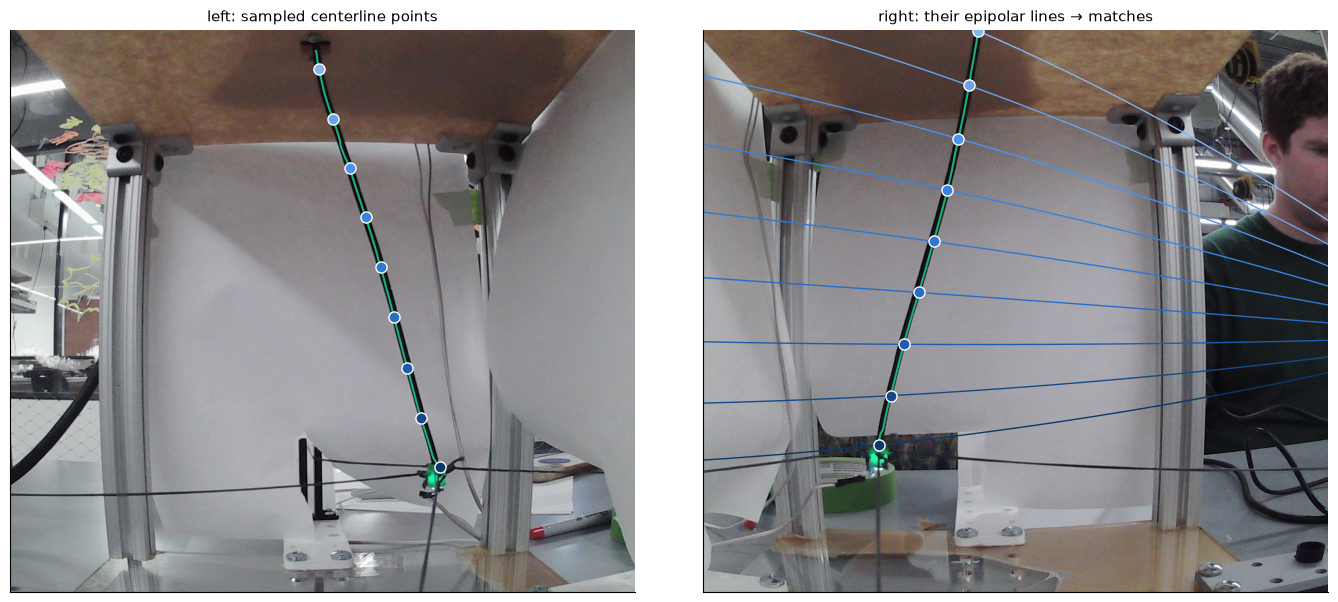

In [7]:
# figure: epipolar matching for one position -- left points (left) and their epipolar lines in the right image (right)
EXAMPLE = "img_r04_c04"
r, cl_l, cl_r = recon[EXAMPLE], seg[EXAMPLE]["l"]["centerline"], seg[EXAMPLE]["r"]["centerline"]
pick = r["idx"][np.linspace(0, len(r["idx"]) - 1, 9).astype(int)]
cols = BLUES(np.linspace(0.25, 1, len(pick)))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(images[EXAMPLE]["l"], cv2.COLOR_BGR2RGB))
axes[0].plot(*cl_l.T, color=C_AUX, lw=1.5)
axes[1].imshow(cv2.cvtColor(images[EXAMPLE]["r"], cv2.COLOR_BGR2RGB))
axes[1].plot(*cl_r.T, color=C_AUX, lw=1.5)
xs = np.linspace(-0.9, 0.9, 400)
for i, c in zip(pick, cols):
    axes[0].plot(*cl_l[i], "o", color=c, mec="white", ms=8)
    l = E @ np.r_[undist(cl_l[i], K0, D0)[0], 1]
    line = np.column_stack([xs, -(l[0] * xs + l[2]) / l[1]])            # epipolar line in normalised right coords
    uv = cv2.projectPoints(np.c_[line, np.ones(len(xs))].reshape(-1, 1, 3), np.zeros(3), np.zeros(3), K1, D1)[0].reshape(-1, 2)
    axes[1].plot(*uv.T, color=c, lw=1)                                  # (curved: lens distortion)
    j = np.flatnonzero(r["idx"] == i)[0]
    hit = cv2.projectPoints(np.r_[r["uv_r"][j], 1].reshape(1, 1, 3), np.zeros(3), np.zeros(3), K1, D1)[0].ravel()
    axes[1].plot(*hit, "o", color=c, mec="white", ms=8)
for a, ttl in zip(axes, ["left: sampled centerline points", "right: their epipolar lines → matches"]):
    a.set_xlim(400, 1600); a.set_ylim(H, 0); a.set_title(ttl); a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

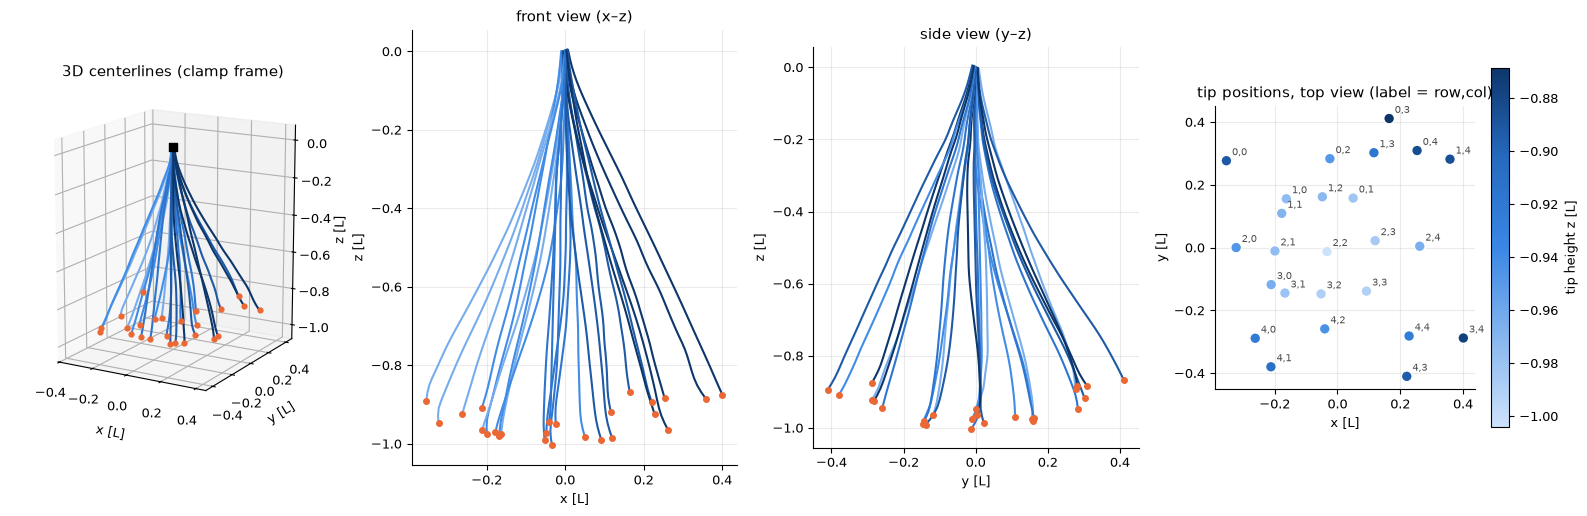

In [8]:
# figure: reconstructed 3D curves (colour = grid column) + projections
col_c = {c: BLUES(v) for c, v in zip(range(N_COLS), np.linspace(0.3, 1, N_COLS))}

fig = plt.figure(figsize=(16, 5.5))
ax = fig.add_subplot(1, 4, 1, projection="3d")
for n, X in zip(names, curves):
    ax.plot(*X.T, color=col_c[grid.loc[n, "col"]], lw=1.5)
ax.scatter(*curves[:, -1].T, color=C_PRED, s=12, depthshade=False)
ax.scatter(0, 0, 0, color="k", marker="s", s=30)
ax.set_xlabel(f"x [{UNIT}]"); ax.set_ylabel(f"y [{UNIT}]"); ax.set_zlabel(f"z [{UNIT}]")
ax.set_aspect("equal")
ax.view_init(elev=15, azim=-60)
ax.set_title("3D centerlines (clamp frame)")

for k, (i, j, ttl) in enumerate([(0, 2, "front view (x–z)"), (1, 2, "side view (y–z)")]):
    a = fig.add_subplot(1, 4, 2 + k)
    for n, X in zip(names, curves):
        a.plot(X[:, i], X[:, j], color=col_c[grid.loc[n, "col"]], lw=1.5)
    a.plot(curves[:, -1, i], curves[:, -1, j], "o", color=C_PRED, ms=4)
    a.set_aspect("equal"); a.set_title(ttl)
    a.set_xlabel(f"{'xyz'[i]} [{UNIT}]"); a.set_ylabel(f"{'xyz'[j]} [{UNIT}]")

a = fig.add_subplot(1, 4, 4)
# note: grid indices don't map monotonically onto tip position (also visible in the raw images), so no lattice lines
T = curves[:, -1]
sc = a.scatter(T[:, 0], T[:, 1], c=T[:, 2], cmap=BLUES, s=60, edgecolor="white", lw=1, zorder=2)
for n, (x, y) in zip(names, curves[:, -1, :2]):
    a.annotate(f"{grid.loc[n, 'row']},{grid.loc[n, 'col']}", (x, y), xytext=(4, 4), textcoords="offset points", fontsize=7, color="0.3")
a.set_aspect("equal"); a.set_title("tip positions, top view (label = row,col)")
a.set_xlabel(f"x [{UNIT}]"); a.set_ylabel(f"y [{UNIT}]")
fig.colorbar(sc, ax=a, shrink=0.7, label=f"tip height z [{UNIT}]")
plt.tight_layout()
plt.show()

## 4. Dataset: sensor readings vs shape

One row per grid position: snapshot means of the 7 photodiodes (normalised by `vref`) and the reconstructed curve.

,row,col,order,vref_uv,vo1_rel,vo2_rel,vo3_rel,vo4_rel,vo5_rel,vo6_rel,vo7_rel,tip_x,tip_y,tip_z
name,,,,,,,,,,,,,,
img_r00_c00,0,0,23,62861,0.94008,0.65458,0.70324,0.71604,0.70278,0.73012,0.60932,-0.35372,0.27693,-0.89158
img_r00_c01,0,1,25,62877,0.94873,0.65562,0.70957,0.72336,0.69989,0.71737,0.60932,0.049992,0.15788,-0.98196
img_r00_c02,0,2,9,63106,1.0667,0.66128,0.72203,0.72051,0.7,0.71932,0.60922,-0.024118,0.28339,-0.94853
img_r00_c03,0,3,12,63161,1.0108,0.6599,0.71495,0.7185,0.67823,0.68967,0.6092,0.16457,0.41136,-0.86846
img_r00_c04,0,4,11,63144,1.0526,0.66122,0.72579,0.72156,0.68543,0.71227,0.60922,0.25362,0.30937,-0.88407
img_r01_c00,1,0,24,62872,0.94461,0.65508,0.70634,0.71798,0.70318,0.72874,0.60933,-0.16289,0.15564,-0.97466
img_r01_c01,1,1,22,62854,0.9743,0.65916,0.72068,0.71692,0.7004,0.72767,0.60935,-0.17754,0.10921,-0.96872
img_r01_c02,1,2,8,63102,1.068,0.66114,0.72536,0.72163,0.70525,0.72235,0.60921,-0.04818,0.16195,-0.97249
img_r01_c03,1,3,10,63117,1.0607,0.66124,0.72358,0.72206,0.69239,0.71322,0.60922,0.11612,0.3024,-0.91793


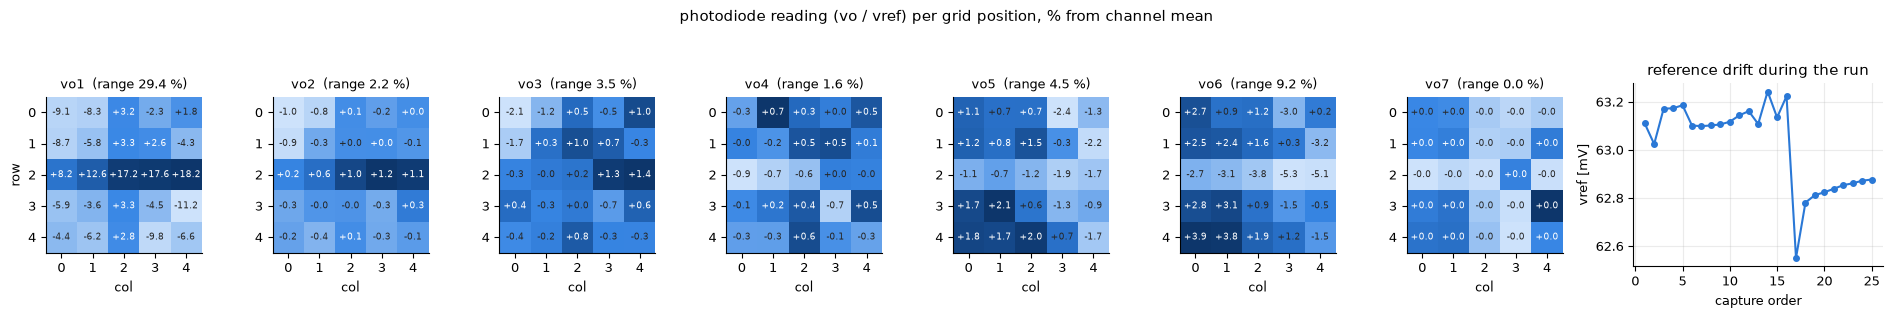

In [9]:
# dataset + figure: each photodiode over the grid
df = grid[["row", "col", "order"]].join(sens[["vref_uv"] + CHANNELS + REL]).join(
    shape_df[["length", "tip_x", "tip_y", "tip_z"]])
with pd.option_context("display.float_format", "{:.5g}".format, "display.width", 250, "display.max_columns", None):
    display(df[["row", "col", "order", "vref_uv"] + REL + ["tip_x", "tip_y", "tip_z"]])

fig, axes = plt.subplots(1, 8, figsize=(19, 3.0), gridspec_kw=dict(width_ratios=[1] * 7 + [1.6]))
for a, f in zip(axes, REL):
    M = df.pivot(index="row", columns="col", values=f).to_numpy()
    rel = (M / M.mean() - 1) * 100                                     # % deviation from the channel mean
    im = a.imshow(rel, cmap=BLUES)
    for (i, j), v in np.ndenumerate(rel):
        a.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5,
               color="white" if v > np.percentile(rel, 60) else "0.15")
    a.set_title(f"{f.split('_')[0]}  (range {np.ptp(rel):.1f} %)", fontsize=9)
    a.set_xlabel("col"); a.set_ylabel("row") if f == REL[0] else None
    a.set_xticks(range(N_COLS)); a.set_yticks(range(N_ROWS)); a.grid(False)
a = axes[-1]
o = df.sort_values("order")
a.plot(o["order"], o["vref_uv"] / 1e3, color=C_MEAS, marker="o", ms=4, lw=1.5)
a.set_xlabel("capture order"); a.set_ylabel("vref [mV]"); a.set_title("reference drift during the run")
fig.suptitle("photodiode reading (vo / vref) per grid position, % from channel mean", y=1.04)
plt.tight_layout()
plt.show()

## 5. Regression: sensors → 3D shape

**Model**: ridge regression from the 6 standardised features `vo_k / vref` (k = 1..6) to the flattened curve (`N_PTS` x 3
coordinates), i.e. a linear map plus the mean shape. With only 25 samples this is deliberately simple.

**Evaluation**: nested leave-one-out. Each of the 25 positions is predicted by a model that never saw it. The ridge strength
α is picked inside each fold by an inner LOO on the remaining 24 samples (closed form via the hat matrix). Baseline = always
predicting the mean training shape.

Errors: *mean point error* = average 3D distance between predicted and measured curve points; *tip error* = distance at s = 1.

In [10]:
# ridge regression with nested leave-one-out CV
ALPHAS = np.logspace(-3, 3, 31)
Xf = df[FEATURES].to_numpy()
Y = curves.reshape(len(names), -1)


def ridge_fit(X, Y, alpha):
    mu, sd = X.mean(0), X.std(0)
    Xs = (X - mu) / sd
    ym = Y.mean(0)
    Wt = np.linalg.solve(Xs.T @ Xs + alpha * np.eye(X.shape[1]), Xs.T @ (Y - ym))
    return dict(mu=mu, sd=sd, ym=ym, W=Wt, alpha=alpha)


def ridge_predict(m, X):
    return ((np.atleast_2d(X) - m["mu"]) / m["sd"]) @ m["W"] + m["ym"]


def point_err(Yp, Yt):
    # mean 3D point distance per sample
    return np.linalg.norm(Yp.reshape(len(Yp), -1, 3) - Yt.reshape(len(Yt), -1, 3), axis=2).mean(1)


def inner_loo_alpha(X, Y):
    # alpha with the lowest closed-form LOO error (standardisation from the training fold)
    Xs = (X - X.mean(0)) / X.std(0)
    Yc = Y - Y.mean(0)
    n = len(X)
    errs = []
    for a in ALPHAS:
        A = np.linalg.solve(Xs.T @ Xs + a * np.eye(X.shape[1]), Xs.T)
        Hd = 1 / n + np.einsum("ij,ji->i", Xs, A)
        res = (Yc - Xs @ (A @ Yc)) / (1 - Hd)[:, None]
        errs.append(np.linalg.norm(res.reshape(n, -1, 3), axis=2).mean())              # mean LOO point error
    return ALPHAS[int(np.argmin(errs))], np.array(errs)


pred_ridge, pred_mean, alphas_used = np.zeros_like(Y), np.zeros_like(Y), []
for i in range(len(names)):
    tr = np.arange(len(names)) != i
    a, _ = inner_loo_alpha(Xf[tr], Y[tr])
    alphas_used.append(a)
    pred_ridge[i] = ridge_predict(ridge_fit(Xf[tr], Y[tr], a), Xf[i])[0]
    pred_mean[i] = Y[tr].mean(0)

P_r, P_m = pred_ridge.reshape(curves.shape), pred_mean.reshape(curves.shape)
res = pd.DataFrame({
    "row": grid["row"], "col": grid["col"],
    "pt_err_ridge": point_err(pred_ridge, Y), "pt_err_mean": point_err(pred_mean, Y),
    "tip_err_ridge": np.linalg.norm(P_r[:, -1] - curves[:, -1], axis=1),
    "tip_err_mean": np.linalg.norm(P_m[:, -1] - curves[:, -1], axis=1),
    "alpha": alphas_used,
}, index=names)

L_mean = shape_df["length"].mean()
summary = pd.DataFrame({
    "mean point error": [res["pt_err_mean"].mean(), res["pt_err_ridge"].mean()],
    "median point error": [res["pt_err_mean"].median(), res["pt_err_ridge"].median()],
    "mean tip error": [res["tip_err_mean"].mean(), res["tip_err_ridge"].mean()],
    "max tip error": [res["tip_err_mean"].max(), res["tip_err_ridge"].max()],
}, index=["mean shape (baseline)", "ridge regression"])
print(f"nested LOO-CV, errors in {UNIT} (fiber length = {L_mean:.3f} {UNIT}); alpha chosen: "
      f"median {np.median(alphas_used):.3g} (range {min(alphas_used):.3g}-{max(alphas_used):.3g})")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)
print(f"ridge vs baseline: point error -{100 * (1 - summary.iloc[1, 0] / summary.iloc[0, 0]):.0f} %, "
      f"tip error -{100 * (1 - summary.iloc[1, 2] / summary.iloc[0, 2]):.0f} %; "
      f"mean point error = {100 * summary.iloc[1, 0] / L_mean:.1f} % of fiber length")

nested LOO-CV, errors in L (fiber length = 1.000 L); alpha chosen: median 0.631 (range 0.251-0.631)


,mean point error,median point error,mean tip error,max tip error
mean shape (baseline),0.1390,0.1256,0.3068,0.5188
ridge regression,0.0926,0.0939,0.2007,0.3477


ridge vs baseline: point error -33 %, tip error -35 %; mean point error = 9.3 % of fiber length


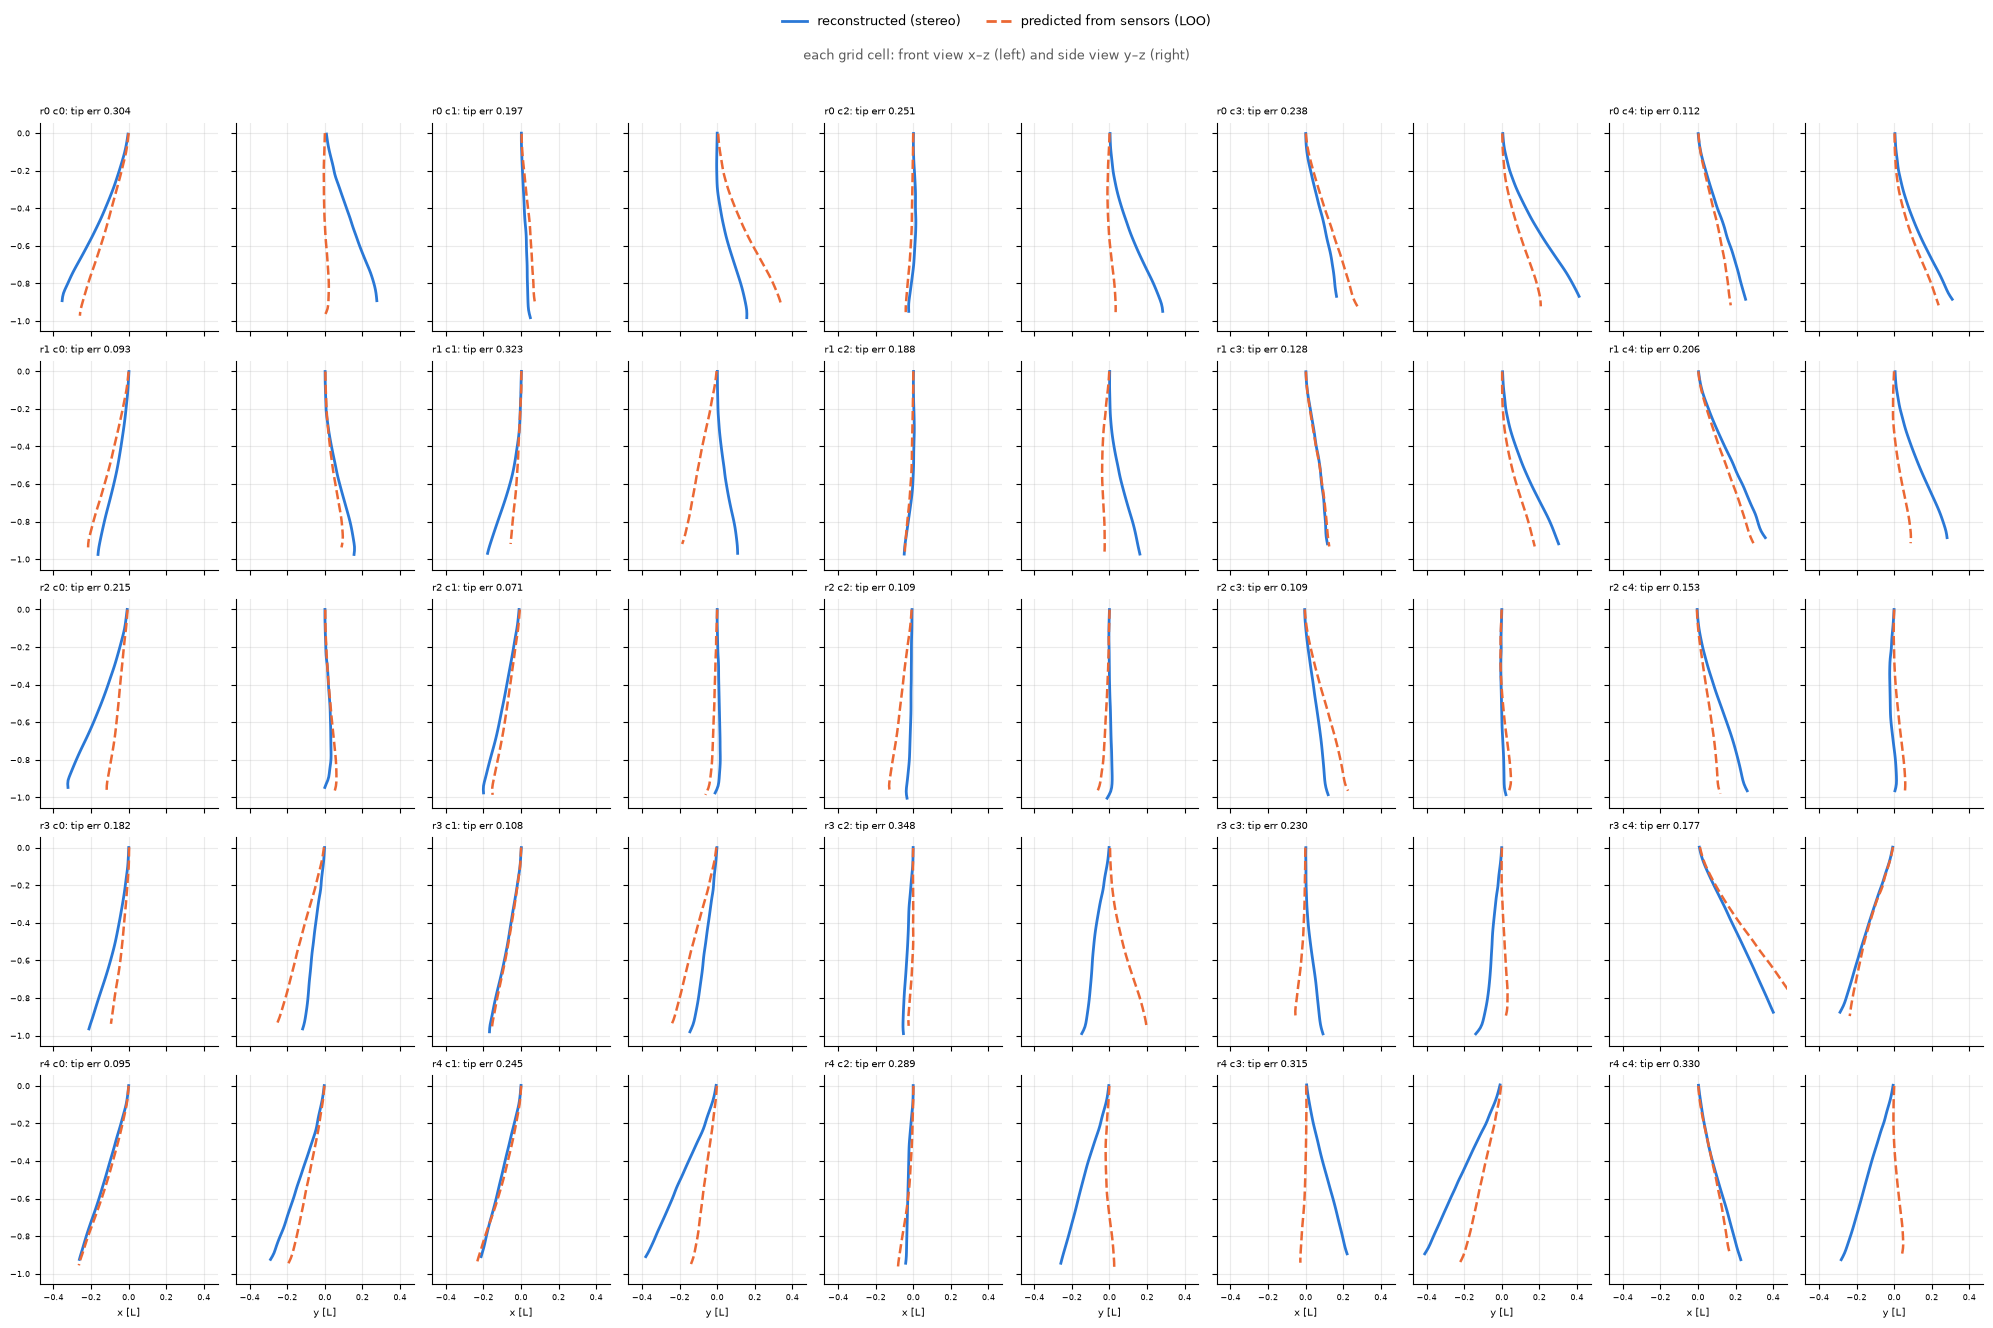

In [11]:
# figure: reconstructed (measured) vs LOO-predicted curves for every grid position, front (x–z) and side (y–z) views
fig, axes = plt.subplots(N_ROWS, 2 * N_COLS, figsize=(2.0 * 2 * N_COLS, 2.6 * N_ROWS), sharex="col", sharey=True)
lim_xy = np.abs(curves[..., :2]).max() * 1.15
for k, n in enumerate(names):
    rr, cc = grid.loc[n, "row"], grid.loc[n, "col"]
    for v, (i, lab) in enumerate([(0, "x"), (1, "y")]):
        a = axes[rr, 2 * cc + v]
        a.plot(curves[k, :, i], curves[k, :, 2], color=C_MEAS, lw=2)
        a.plot(P_r[k, :, i], P_r[k, :, 2], "--", color=C_PRED, lw=1.8)
        a.set_xlim(-lim_xy, lim_xy)
        a.set_aspect("equal")
        a.tick_params(labelsize=6)
        if v == 0:
            a.set_title(f"r{rr} c{cc}: tip err {res.loc[n, 'tip_err_ridge']:.3f}", fontsize=7.5, loc="left")
        if rr == N_ROWS - 1:
            a.set_xlabel(f"{lab} [{UNIT}]", fontsize=7)
axes[0, 0].plot([], [], color=C_MEAS, label="reconstructed (stereo)")
axes[0, 0].plot([], [], "--", color=C_PRED, label="predicted from sensors (LOO)")
fig.legend(loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("each grid cell: front view x–z (left) and side view y–z (right)", y=0.985, fontsize=9, color="0.35")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

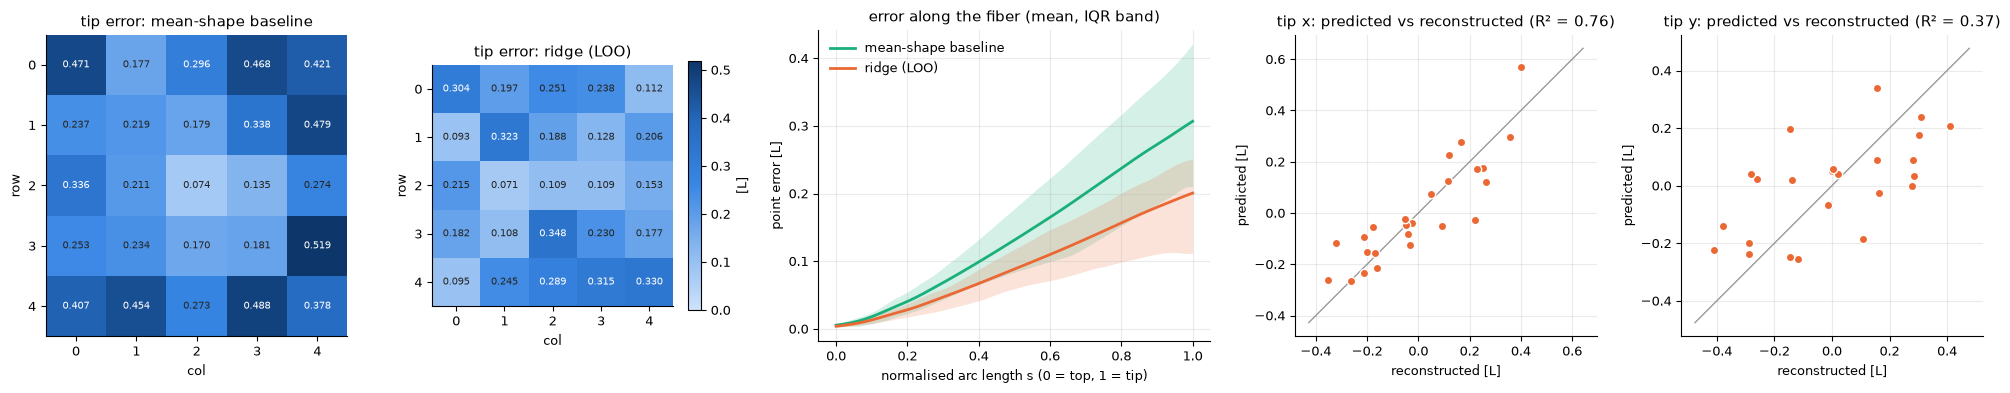

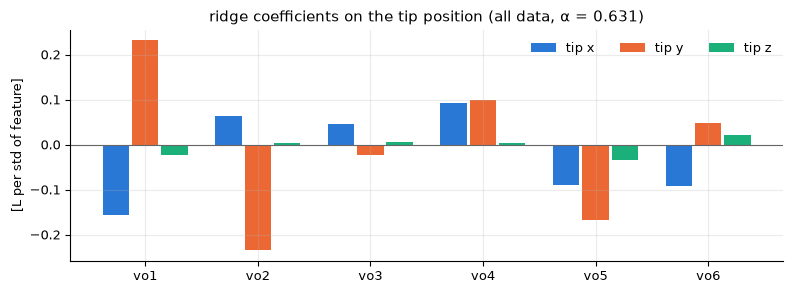

In [12]:
# figure: error summary -- per-position heatmaps, error along the fiber, tip parity
fig, axes = plt.subplots(1, 5, figsize=(20, 4), gridspec_kw=dict(width_ratios=[1, 1, 1.3, 1, 1]))
vmax = res[["tip_err_ridge", "tip_err_mean"]].to_numpy().max()
for a, col, ttl in [(axes[0], "tip_err_mean", "tip error: mean-shape baseline"), (axes[1], "tip_err_ridge", "tip error: ridge (LOO)")]:
    M = res.pivot(index="row", columns="col", values=col).to_numpy()
    im = a.imshow(M, cmap=BLUES, vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        a.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7, color="white" if v > 0.55 * vmax else "0.15")
    a.set_title(ttl); a.set_xlabel("col"); a.set_ylabel("row"); a.grid(False)
    a.set_xticks(range(N_COLS)); a.set_yticks(range(N_ROWS))
fig.colorbar(im, ax=axes[1], shrink=0.8, label=f"[{UNIT}]")

a = axes[2]
s = np.linspace(0, 1, N_PTS)
for P, c, lab in [(P_m, C_AUX, "mean-shape baseline"), (P_r, C_PRED, "ridge (LOO)")]:
    e = np.linalg.norm(P - curves, axis=2)
    a.fill_between(s, np.percentile(e, 25, 0), np.percentile(e, 75, 0), color=c, alpha=0.18, lw=0)
    a.plot(s, e.mean(0), color=c, label=lab)
a.set_xlabel("normalised arc length s (0 = top, 1 = tip)"); a.set_ylabel(f"point error [{UNIT}]")
a.set_title("error along the fiber (mean, IQR band)"); a.legend(frameon=False)

for a, k in zip(axes[3:], [0, 1]):
    lo, hi = min(curves[:, -1, k].min(), P_r[:, -1, k].min()), max(curves[:, -1, k].max(), P_r[:, -1, k].max())
    pad = 0.08 * (hi - lo)
    a.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="0.6", lw=1)
    a.scatter(curves[:, -1, k], P_r[:, -1, k], color=C_PRED, s=36, edgecolor="white", lw=1, zorder=3)
    r2 = 1 - np.sum((P_r[:, -1, k] - curves[:, -1, k]) ** 2) / np.sum((curves[:, -1, k] - curves[:, -1, k].mean()) ** 2)
    a.set_title(f"tip {'xy'[k]}: predicted vs reconstructed (R² = {r2:.2f})")
    a.set_xlabel(f"reconstructed [{UNIT}]"); a.set_ylabel(f"predicted [{UNIT}]"); a.set_aspect("equal")
plt.tight_layout()
plt.show()

# which photodiodes matter: standardised coefficients of the full-data model on tip x / y / z
alpha_all, _ = inner_loo_alpha(Xf, Y)
model = ridge_fit(Xf, Y, alpha_all)
coef_tip = model["W"].reshape(len(FEATURES), N_PTS, 3)[:, -1, :]
fig, ax = plt.subplots(figsize=(8, 3))
w = 0.26
for k, c in enumerate([C_MEAS, C_PRED, C_AUX]):
    ax.bar(np.arange(len(FEATURES)) + (k - 1) * w, coef_tip[:, k], w * 0.9, color=c, label=f"tip {'xyz'[k]}")
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xticks(range(len(FEATURES)), [f.split("_")[0] for f in FEATURES])
ax.set_ylabel(f"[{UNIT} per std of feature]"); ax.set_title(f"ridge coefficients on the tip position (all data, α = {alpha_all:.3g})")
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

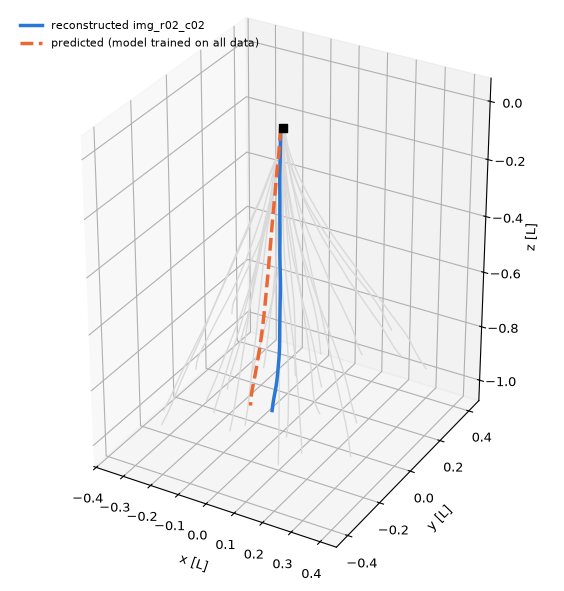

In [13]:
# predict a 3D shape from a new set of photodiode readings (final model = all 25 positions)
def predict_shape(readings_uv, vref_uv):
    # readings_uv: 7 photodiode means [uV] (vo1..vo7); returns (N_PTS, 3) curve in the clamp frame
    rel = dict(zip(REL, np.asarray(readings_uv, float) / vref_uv))
    return ridge_predict(model, np.array([rel[f] for f in FEATURES]))[0].reshape(N_PTS, 3)


query = "img_r02_c02"                                                   # example: reuse one position's readings
Xq = predict_shape(df.loc[query, CHANNELS].to_numpy(), df.loc[query, "vref_uv"])
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
for X in curves:
    ax.plot(*X.T, color="0.85", lw=1)
ax.plot(*curves[names.index(query)].T, color=C_MEAS, lw=2.5, label=f"reconstructed {query}")
ax.plot(*Xq.T, "--", color=C_PRED, lw=2.5, label="predicted (model trained on all data)")
ax.scatter(0, 0, 0, color="k", marker="s", s=30)
ax.set_xlabel(f"x [{UNIT}]"); ax.set_ylabel(f"y [{UNIT}]"); ax.set_zlabel(f"z [{UNIT}]")
ax.set_aspect("equal"); ax.legend(loc="upper left", frameon=False, fontsize=8)
plt.tight_layout()
plt.show()